<a href="https://colab.research.google.com/github/Meeran11-A/ECA5801-IOE-AND-AI-DRIVEN-SYSTEM/blob/main/IOE_EXP4_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXPERIMENT 7: IoE PROTOCOL PERFORMANCE


,Protocol,Packets Sent,Packets Received,Throughput (kbps),Average Delay (ms),PDR (%),Energy (J)
0,Zigbee,1000,951,76.08,20.074,95.1,1.15
1,6LoWPAN,1000,906,72.48,35.483,90.6,1.40
2,NB-IoT,1000,982,78.56,79.693,98.2,2.70


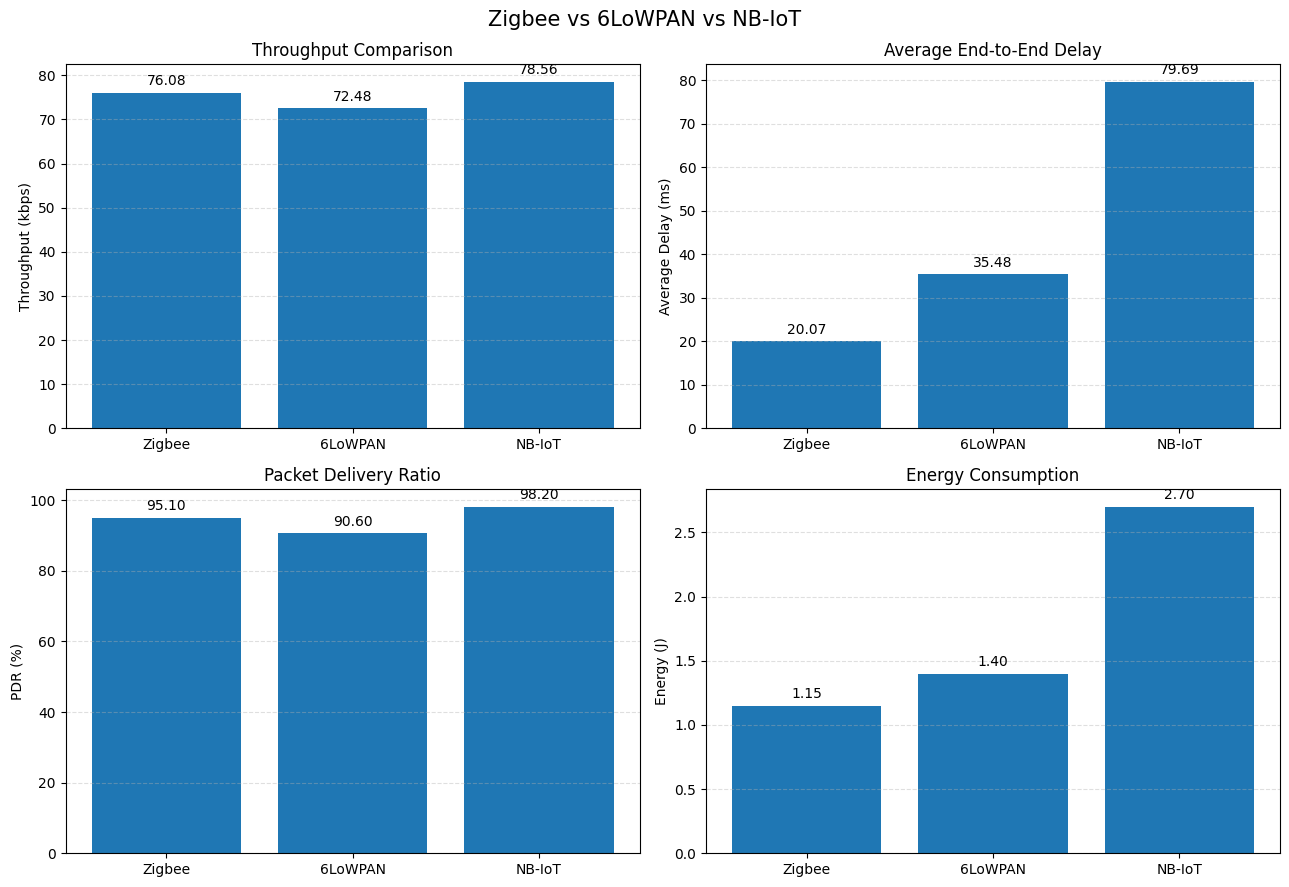


SIMULATION OBSERVATIONS
-----------------------------------
Highest throughput: NB-IoT
Lowest average delay: Zigbee
Highest packet delivery ratio: NB-IoT
Lowest modeled energy consumption: Zigbee

Experiment 7 completed.


In [2]:

# EXPERIMENT 7
# Comparative Performance Evaluation of Zigbee, 6LoWPAN and NB-IoT
# Google Colab - Python-based illustrative simulation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. SIMULATION PARAMETERS
# --------------------------------------------------

np.random.seed(42)

protocols = ["Zigbee", "6LoWPAN", "NB-IoT"]

NUM_PACKETS = 1000
PACKET_SIZE_BYTES = 100
SIMULATION_TIME = 10       # seconds

# Illustrative assumptions for each protocol:
# delay mean (ms), packet success probability,
# transmit power (W), receive power (W)

parameters = {
    "Zigbee":  {"delay": 20, "pdr": 0.95,
                "tx_power": 0.060, "rx_power": 0.045},
    "6LoWPAN": {"delay": 35, "pdr": 0.92,
                "tx_power": 0.080, "rx_power": 0.050},
    "NB-IoT":  {"delay": 80, "pdr": 0.98,
                "tx_power": 0.200, "rx_power": 0.060}
}

results = []

# --------------------------------------------------
# 2. SIMULATE PACKET TRANSMISSION
# --------------------------------------------------

for protocol in protocols:

    p = parameters[protocol]

    # Simulate packet delivery
    delivered = np.random.binomial(
        NUM_PACKETS, p["pdr"]
    )

    # Packet delivery ratio
    actual_pdr = delivered / NUM_PACKETS * 100

    # Simulated packet delays
    packet_delays = np.random.normal(
        loc=p["delay"],
        scale=p["delay"] * 0.20,
        size=delivered
    )

    packet_delays = np.maximum(packet_delays, 0.1)
    avg_delay = np.mean(packet_delays)

    # Application-level throughput in kbps
    throughput = (
        delivered * PACKET_SIZE_BYTES * 8
        / SIMULATION_TIME / 1000
    )

    # Illustrative energy model:
    # Assume one transmission and one reception
    # per generated packet, over the simulation.
    tx_energy = (
        p["tx_power"] * SIMULATION_TIME
    )
    rx_energy = (
        p["rx_power"] * SIMULATION_TIME
    )

    # Add a small illustrative idle energy component
    idle_energy = 0.01 * SIMULATION_TIME
    total_energy = tx_energy + rx_energy + idle_energy

    results.append({
        "Protocol": protocol,
        "Packets Sent": NUM_PACKETS,
        "Packets Received": delivered,
        "Throughput (kbps)": throughput,
        "Average Delay (ms)": avg_delay,
        "PDR (%)": actual_pdr,
        "Energy (J)": total_energy
    })

# --------------------------------------------------
# 3. DISPLAY RESULTS TABLE
# --------------------------------------------------

df = pd.DataFrame(results)

print("EXPERIMENT 7: IoE PROTOCOL PERFORMANCE")
print("=" * 55)
display(df.round(3))

# --------------------------------------------------
# 4. PERFORMANCE COMPARISON GRAPHS
# --------------------------------------------------

metrics = [
    ("Throughput (kbps)", "Throughput Comparison"),
    ("Average Delay (ms)", "Average End-to-End Delay"),
    ("PDR (%)", "Packet Delivery Ratio"),
    ("Energy (J)", "Energy Consumption")
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (column, title) in zip(axes.flat, metrics):
    bars = ax.bar(df["Protocol"], df[column])
    ax.set_title(title, fontsize=12)
    ax.set_ylabel(column)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.bar_label(bars, fmt="%.2f", padding=3)

plt.suptitle(
    "Zigbee vs 6LoWPAN vs NB-IoT",
    fontsize=15
)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 5. PRINT AUTOMATIC OBSERVATIONS
# --------------------------------------------------

print("\nSIMULATION OBSERVATIONS")
print("-" * 35)

best_throughput = df.loc[
    df["Throughput (kbps)"].idxmax(), "Protocol"
]
lowest_delay = df.loc[
    df["Average Delay (ms)"].idxmin(), "Protocol"
]
best_pdr = df.loc[df["PDR (%)"].idxmax(), "Protocol"]
lowest_energy = df.loc[df["Energy (J)"].idxmin(), "Protocol"]

print("Highest throughput:", best_throughput)
print("Lowest average delay:", lowest_delay)
print("Highest packet delivery ratio:", best_pdr)
print("Lowest modeled energy consumption:", lowest_energy)

print("\nExperiment 7 completed.")
